In [1]:
from pathlib import Path
import sys
from sklearn.metrics import mean_squared_error, mean_absolute_error

from scipy.stats import norm
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from itertools import product
# Agregar el path del directorio "code"
code_path = Path("../Code").resolve()
if str(code_path) not in sys.path:
    sys.path.insert(0, str(code_path))

from scipy.stats import norm
from TimeSeriesLib import MeanRollingForecast, LastRollingForecast, SarimaxRollingForecast

In [2]:
#!pip install statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import acf
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [3]:
df = pd.read_csv('../datasets/widget_sales.csv')
df.head()

,widget_sales
0,50.496714
1,50.805493
2,51.477758
3,53.542228
4,54.873108


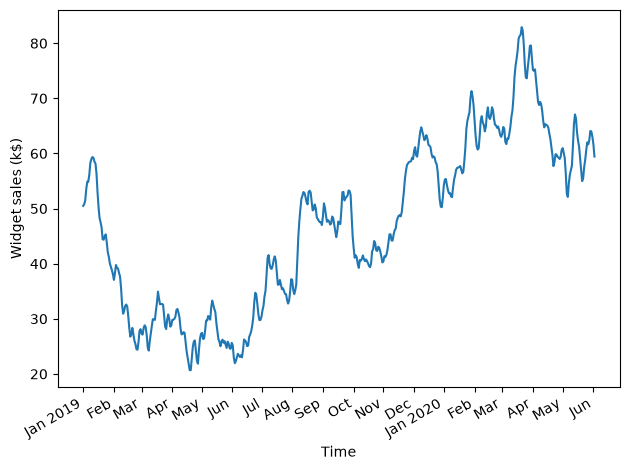

In [4]:
fig, ax = plt.subplots()

ax.plot(df['widget_sales'])
ax.set_xlabel('Time')
ax.set_ylabel('Widget sales (k$)')

plt.xticks(
    [0, 30, 57, 87, 116, 145, 175, 204, 234, 264, 293, 323, 352, 382, 409, 439, 468, 498], 
    ['Jan 2019', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan 2020', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Parece no ser estacionaria, pero igualmente lo chequeamos

In [5]:
ADF_result = adfuller(df['widget_sales'])
print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

ADF Statistic: -1.512166206935903
p-value: 0.5274845352272614


El p-valor es alto, por tanto NO rechazamos la hipótesis nula de que la serie tiene una raíz unitaria. La serie no es estacionaria, requiere ser diferenciada.

Aplicamos transformación, diferencia de primer orden

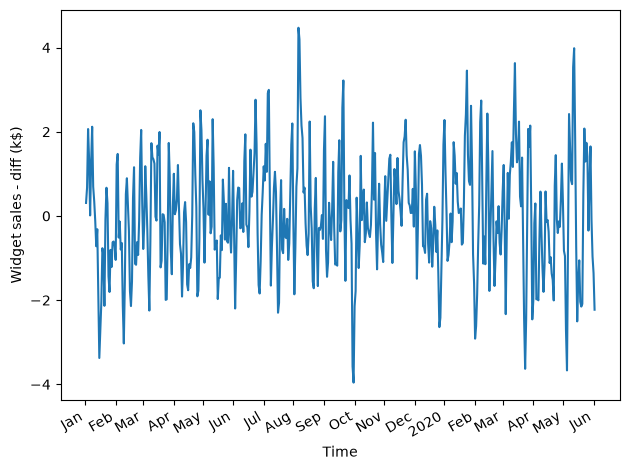

In [6]:
df["widget_sales_diff"] = df['widget_sales'].diff()
fig, ax = plt.subplots()

ax.plot(df["widget_sales_diff"])
ax.set_xlabel('Time')
ax.set_ylabel('Widget sales - diff (k$)')

plt.xticks(
    [0, 30, 57, 87, 116, 145, 175, 204, 234, 264, 293, 323, 352, 382, 409, 439, 468, 498], 
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', '2020', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Chequeamos si ahora tenemos una serie estacionaria y efectivamente lo es

In [7]:
ADF_result = adfuller(df['widget_sales_diff'].dropna())
print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

ADF Statistic: -10.576657780341959
p-value: 7.076922818587193e-19


Mejora 2026. No se trabaja sobre la serie diferenciada. Evitamos reconstrucción. Una vez que obtenemos la cantidad de veces que necesitamos diferenciar le pasamos el trabajo a la biblioteca Sarimax.

Entonces hay que diferenciar una vez:

In [8]:
d = 1

Ahora chequeamos autocorrelación, vemos que los coeficientes son significativos hasta el orden 2, por tanto tenemos un moving average process de orden 2, podemos usar entonces un modelo de MA de orden dos para realizar pronosticos sobre nuestra serie.

In [9]:
alpha = 0.05
acv = acf(df['widget_sales_diff'].dropna(), nlags=5, alpha=alpha)
acv[0]

array([ 1.        ,  0.60988516,  0.14099242, -0.03784949, -0.04582061,
        0.00697026])

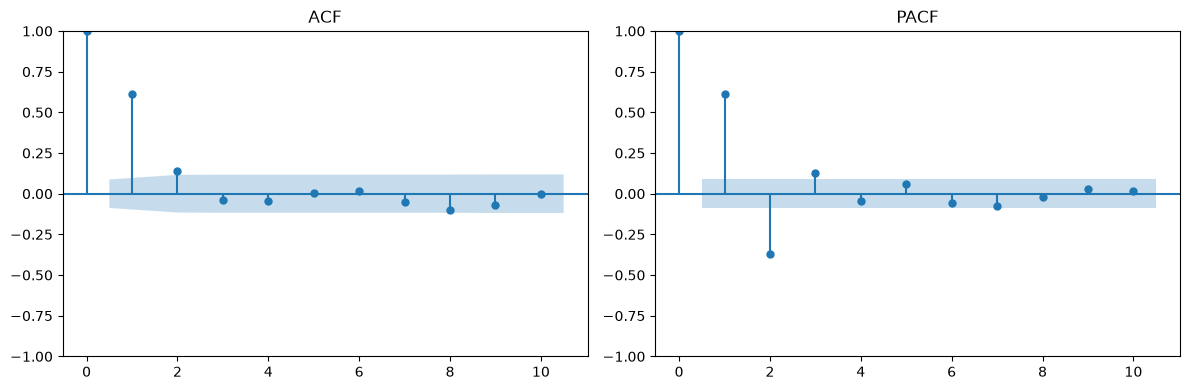

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF
plot_acf(df['widget_sales_diff'].dropna(), ax=axes[0], lags=10, alpha=0.05)
axes[0].set_title("ACF")

# PACF
plot_pacf(df['widget_sales_diff'].dropna(), ax=axes[1], lags=10, alpha=0.05, method="ywm")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

In [11]:
df_train = df.iloc[:int(0.9*len(df))][["widget_sales"]]
df_test = df.iloc[int(0.9*len(df)):][["widget_sales"]]
print(len(df_train))
print(len(df_test))

450
50


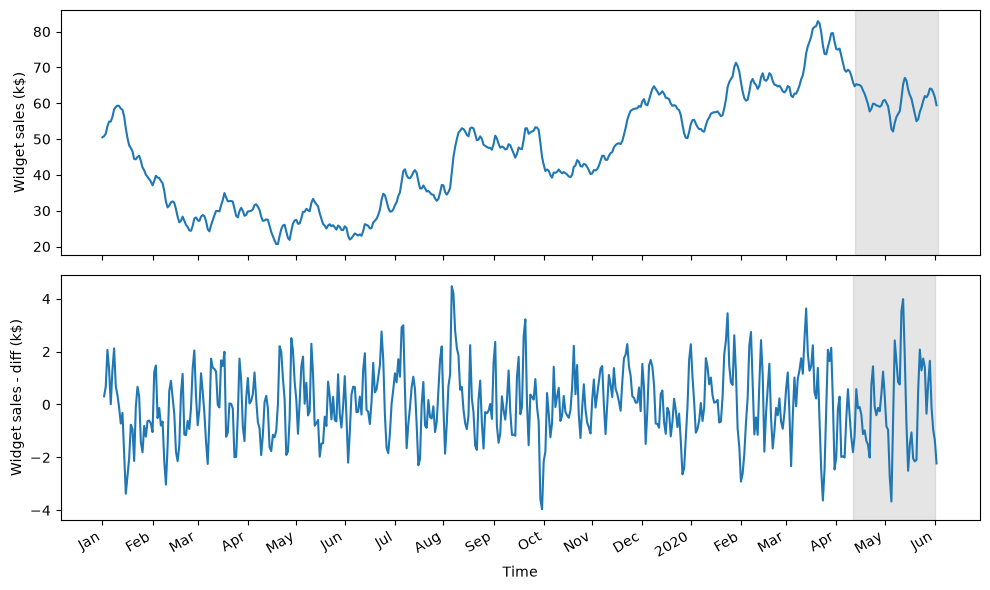

In [12]:
fig, (ax1, ax2) = plt.subplots(figsize=(10, 6), nrows=2, ncols=1, sharex=True)
ax1.plot(df['widget_sales'])
ax1.set_xlabel('Time')
ax1.set_ylabel('Widget sales (k$)')
ax1.axvspan(450, 500, color='#808080', alpha=0.2)
ax2.plot(df['widget_sales_diff'])
ax2.set_xlabel('Time')
ax2.set_ylabel('Widget sales - diff (k$)')
ax2.axvspan(449, 498, color='#808080', alpha=0.2)
plt.xticks(
    [0, 30, 57, 87, 116, 145, 175, 204, 234, 264, 293, 323, 352, 382, 409, 439, 468, 498], 
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', '2020', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Version 2026

In [13]:
df["widget_sales"]

0      50.496714
1      50.805493
2      51.477758
3      53.542228
4      54.873108
         ...    
495    64.087371
496    63.992081
497    63.029894
498    61.671797
499    59.443839
Name: widget_sales, Length: 500, dtype: float64

-------------------

In [14]:
window  = 1 # Solo un paso adelante.
train_percent = 0.9
#Demora 13 minutos...
ps      = range(0, 8, 1)    
qs      = range(0, 8, 1)
d       = 1 #Esto ya se que es uno


order_list = list(product(ps, qs))

results = []
for p, q in order_list:
    try:
        model = SarimaxRollingForecast(window=window, train_percent=train_percent, target_col="widget_sales", order=(p, d, q))
        model.backtest(df[["widget_sales"]])
        
        score = model.score()
        results.append([(p, q), score])
        
    except Exception as e:
        print(f"Error con la orden ({p}, {q}), omitiendo... {e}")
        continue

Error con la orden (6, 5), omitiendo... LU decomposition error.


In [20]:
result_df = pd.DataFrame(results)
result_df.columns = ['(p,q)', 'MSE']
#Sort in ascending order, lower MSE is better
result_df = result_df.sort_values(by='MSE', ascending=True).reset_index(drop=True)
result_df.loc[:5,:]

,"(p,q)",MSE
0,"(7, 1)",1.100609
1,"(7, 0)",1.100909
2,"(7, 5)",1.112458
3,"(6, 2)",1.118253
4,"(1, 4)",1.118791
5,"(0, 5)",1.118814


Mean: 18.39, Last: 2.35, ma: 1.11


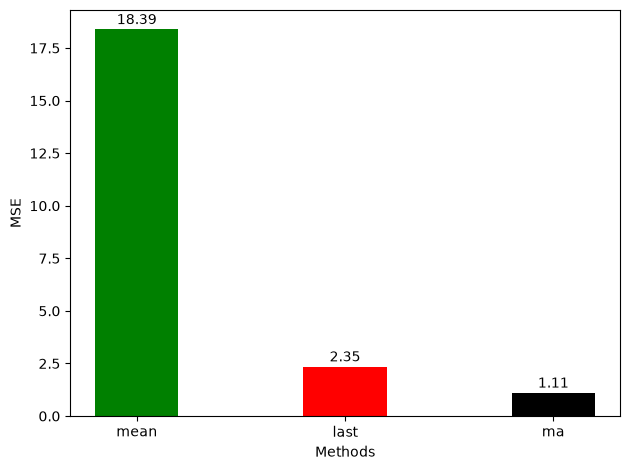

In [ ]:
window = 1
#Dejo mas datos en test para valorar mejor los residuos
train_percent = 0.7
d = 1
result = {}
estimators = {}
estimators["mean"]      = MeanRollingForecast(window=window, train_percent=train_percent, mean_steps=10) #, mean_steps=10
estimators["last"]      = LastRollingForecast(window=window, train_percent=train_percent)
estimators["ma"]        = SarimaxRollingForecast(window=window, train_percent=train_percent, order=(7,d,1), target_col="widget_sales") #p = 1, d = 1, q = 1


for k, v in estimators.items():
    y_pred = v.backtest(df[["widget_sales"]])
    df[k] = y_pred
    #result[k].append(v.score())
print("Mean: {:.2f}, Last: {:.2f}, ma: {:.2f}".format(estimators["mean"].score(), estimators["last"].score(), estimators["ma"].score()))
fig, ax = plt.subplots()
x = ['mean', 'last', 'ma']
y = [estimators["mean"].score(), estimators["last"].score(), estimators["ma"].score()]
ax.bar(x, y, width=0.4, color=['g', 'r', 'k'])
ax.set_xlabel('Methods')
ax.set_ylabel('MSE')
#ax.set_ylim(0, 5)
for index, value in enumerate(y):
    plt.text(x=index, y=value+0.25, s=str(round(value, 2)), ha='center')
plt.tight_layout()
plt.show()




¿Serán normales los residuos?

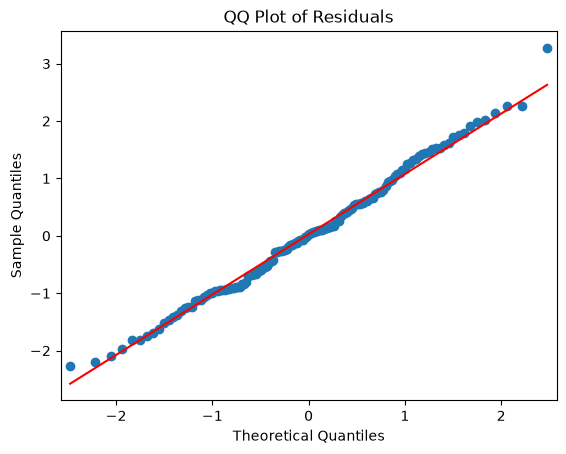

In [36]:
residuals = estimators["ma"].resid_
qqplot(residuals, line='s')
plt.title('QQ Plot of Residuals')
plt.show()


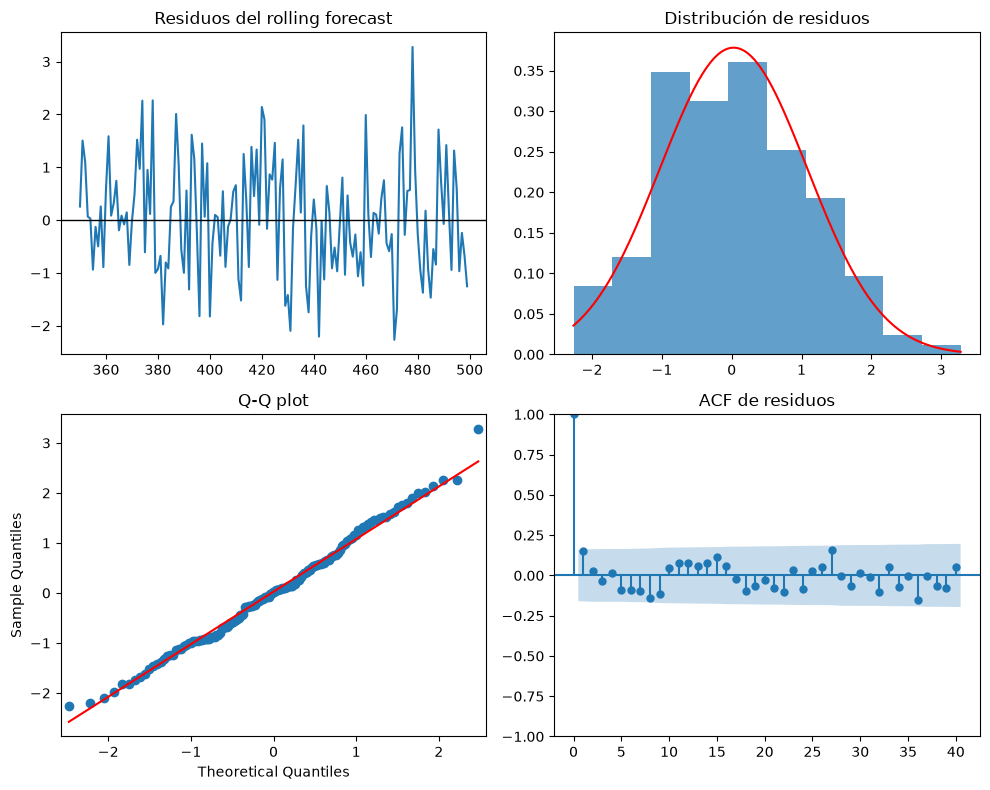

In [37]:
residuals = estimators["ma"].resid_.dropna()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Residuos a lo largo del tiempo
axes[0, 0].plot(residuals.index, residuals)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Residuos del rolling forecast")

# Distribución de los residuos comparada con una normal
axes[0, 1].hist(residuals, bins="auto", density=True, alpha=0.7)
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[0, 1].plot(x, norm.pdf(x, residuals.mean(), residuals.std()), color="red")
axes[0, 1].set_title("Distribución de residuos")

# Gráfico Q-Q
qqplot(residuals, line="s", ax=axes[1, 0])
axes[1, 0].set_title("Q-Q plot")

# Autocorrelación de los residuos
lags = min(40, len(residuals) // 2 - 1)
plot_acf(residuals, lags=lags, ax=axes[1, 1])
axes[1, 1].set_title("ACF de residuos")

plt.tight_layout()
plt.show()

p-valor mayor que 0.05, no rechazamos la hipótesis nula y concluimos que los residuos son independientes y no correlacionados.

In [38]:
acorr_ljungbox(residuals, np.arange(1, 11, 1)).iloc[0:1, 1]

1    0.062446
Name: lb_pvalue, dtype: float64

Con lo justo...